# 💦Analisis de consumos de agua potable del Parque Industrial (2022-2026)

## ℹ Introducción


Mi nombre es Trinidad Sestelo Cangelli, soy Ingeniera Civil y actualmente trabajo en Obras Sanitarias Sociedad de Estado (OSSE) de Mar del Plata, en la Gerencia Técnica, donde me desempeño dentro del área de Proyectos de Agua y Mejoramiento Operativo.

Mi trabajo consiste en el desarrollo de proyectos de infraestructura de agua potable, participando en el análisis de distintas problemáticas y en la elaboración de soluciones técnicas orientadas a mejorar los sistemas de abastecimiento. En este marco, considero que la incorporación de herramientas de análisis de datos representa una oportunidad para complementar mi formación profesional, ampliar mis capacidades técnicas y aprovechar mejor la información disponible en la empresa para el desarrollo de proyectos.

El presente documento tiene como objetivo analizar la evolución de los consumos de agua potable de las empresas que se desarrollan en el Parque Industrial General Savio `PIGS` de la ciudad de Mar del Plata.

Al ser un informe que se presentará como Trabajo Integrador del curso de Herramientas Básicas para el Análisis de Datos dictado por la UTN, se quitaron de los datos presentados, los Nombres y Direcciones de la empresas involucradas.


## ❓ Preguntas

1.  ¿Cuántas empresas comparten propósito/tipo de industria en el PIGS? Enfocado a explicar el Tipo de Ocupacion del PIGS

2.  ¿Cuál es la evolución del Volumen de Agua entregado al PIGS en los ultimos 5 años? Diferenciar Volumenes entregados por la Red y los de Pozos privados.

3.  ¿Cuáles son las empresas que tienen pozos de explotación propios y cuanto consumen en un mes promedio?

4.  ¿Cuáles son las 5 empresas con mayores consumos en el último año y a que tipo de industria se dedican?

5.  ¿Cómo es la distribucion de consumos de agua segun tipo de industria en el úiltimo año?

## ⏫ Origen y carga de los datos

Los datos a analizar fueron extraidos bajo el formato EXCEL de la base de datos de la Gerencia Comercial utilizando SQL.

Se pidió a dicha gerencia, que nos faciliten la información de las mediciones de volumenes de agua registrados en los caudalimetros correspondientes a las conexiones de todas las empresas que se desarrollan en el Parque Industrial, en los ultimos 5 años.


In [1]:
import pandas as pd

In [2]:
data=pd.read_excel("/content/drive/MyDrive/Z-Academico Analisis Datos/PIGS - Parque Industrial/0 - Datos/PIGS_Consumo_2022-26 (AD).xlsx")

print("---Previsualizar excel cargado---")

data

---Previsualizar excel cargado---


,NROIMPONIBLE,DENOMMULTIPROPOSITO,ESTADO,ANIO,CUOTA,NROPUNTO,NROMEDIDOR,FECHALECTURAANT,ESTADOMEDIDORANT,FECHALECTURA,ESTADOMEDIDOR,CONSUMOMEDIDOR,CODTIPOMEDIDOR
0,58388000,PLANTA PROCES.PESCAD,Normal,2022,12,1,C16-N001330,27/10/2022,0,24/11/2022,0,0,Red
1,58388000,PLANTA PROCES.PESCAD,Normal,2023,1,1,C16-N001330,24/11/2022,0,19/12/2022,0,0,Red
2,58388000,PLANTA PROCES.PESCAD,Normal,2023,2,1,C16-N001330,19/12/2022,0,17/01/2023,0,0,Red
3,58388000,PLANTA PROCES.PESCAD,Normal,2023,3,1,C16-N001330,17/01/2023,0,17/02/2023,0,0,Red
4,58388000,PLANTA PROCES.PESCAD,Normal,2023,4,1,C16-N001330,17/02/2023,0,17/03/2023,0,0,Red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6329,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,9,2,7011245,14/07/2026,971886,14/08/2026,1047707,75821,Red
6330,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,10,1,C16N001386,14/08/2026,7000,15/09/2026,7000,0,Red
6331,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,10,2,7011245,14/08/2026,1047707,15/09/2026,1141366,93659,Red
6332,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,11,1,C16N001386,15/09/2026,7000,16/10/2026,7000,0,Red


"**data**"

**Diccionario de Columnas:**

* `NROIMPONIBLE`: Numero de cuenta, ID empresa.

* `DENOMMULTIPROPOSITO`: Tipo de industria.

* `ESTADO`: Estado de la conexión de agua.

* `ANIO`: Año de facturación.

* `CUOTA`: Cuota de facturación.

* `NROPUNTO`: Nro de conexion de una misma empresa (algunas tienen varias conexiones).

* `NROMEDIDOR`: ID del medidor colocado.

* `FECHALECTURAANT`: Fecha de la anterior medición registrada.

* `ESTADOMEDIDORANT`: Anterior medición registrada del caudalimetro [m3].

* `FECHALECTURA`: Fecha de lectura última.

* `ESTADOMEDIDOR`: Última lectura del caudalímetro [m3].

* `CONSUMOMEDIDOR`: `ESTADOMEDIDOR` - `ESTADOMEDIDORANTERIOR` [m3].

* `CODTIPOMEDIDOR`: Diferencia si el medidor entrega agua de la red o de un pozo de explotacion propio de la empresa.

## 🔃 Exploración y Limpieza de datos

In [3]:
data.shape

(6334, 13)

In [4]:
#previsualizacion de formatos de las variables

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6334 entries, 0 to 6333
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   NROIMPONIBLE         6334 non-null   int64 
 1   DENOMMULTIPROPOSITO  6334 non-null   object
 2   ESTADO               6334 non-null   object
 3   ANIO                 6334 non-null   int64 
 4   CUOTA                6334 non-null   int64 
 5   NROPUNTO             6334 non-null   int64 
 6   NROMEDIDOR           6334 non-null   object
 7   FECHALECTURAANT      6334 non-null   object
 8   ESTADOMEDIDORANT     6334 non-null   int64 
 9   FECHALECTURA         6334 non-null   object
 10  ESTADOMEDIDOR        6334 non-null   int64 
 11  CONSUMOMEDIDOR       6334 non-null   int64 
 12  CODTIPOMEDIDOR       6334 non-null   object
dtypes: int64(7), object(6)
memory usage: 643.4+ KB


In [5]:
data.head(5)

,NROIMPONIBLE,DENOMMULTIPROPOSITO,ESTADO,ANIO,CUOTA,NROPUNTO,NROMEDIDOR,FECHALECTURAANT,ESTADOMEDIDORANT,FECHALECTURA,ESTADOMEDIDOR,CONSUMOMEDIDOR,CODTIPOMEDIDOR
0,58388000,PLANTA PROCES.PESCAD,Normal,2022,12,1,C16-N001330,27/10/2022,0,24/11/2022,0,0,Red
1,58388000,PLANTA PROCES.PESCAD,Normal,2023,1,1,C16-N001330,24/11/2022,0,19/12/2022,0,0,Red
2,58388000,PLANTA PROCES.PESCAD,Normal,2023,2,1,C16-N001330,19/12/2022,0,17/01/2023,0,0,Red
3,58388000,PLANTA PROCES.PESCAD,Normal,2023,3,1,C16-N001330,17/01/2023,0,17/02/2023,0,0,Red
4,58388000,PLANTA PROCES.PESCAD,Normal,2023,4,1,C16-N001330,17/02/2023,0,17/03/2023,0,0,Red


In [6]:
#cambiamos los formatos de las variables

data['NROIMPONIBLE']=data['NROIMPONIBLE'].astype('str')

data['FECHALECTURAANT']=pd.to_datetime(data['FECHALECTURAANT'])

data['ESTADOMEDIDORANT']=data['ESTADOMEDIDORANT'].astype('float64')

data['FECHALECTURA']=pd.to_datetime(data['FECHALECTURA'])

data['ESTADOMEDIDOR']=data['ESTADOMEDIDOR'].astype('float64')

data['CONSUMOMEDIDOR']=data['CONSUMOMEDIDOR'].astype('float64')

display(data.dtypes)
display(data.head(3))
display(data.tail(3))

/tmp/ipykernel_2616/4202695393.py:5: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['FECHALECTURAANT']=pd.to_datetime(data['FECHALECTURAANT'])
/tmp/ipykernel_2616/4202695393.py:9: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  data['FECHALECTURA']=pd.to_datetime(data['FECHALECTURA'])


,0
NROIMPONIBLE,object
DENOMMULTIPROPOSITO,object
ESTADO,object
ANIO,int64
CUOTA,int64
NROPUNTO,int64
NROMEDIDOR,object
FECHALECTURAANT,datetime64[ns]
ESTADOMEDIDORANT,float64
FECHALECTURA,datetime64[ns]


,NROIMPONIBLE,DENOMMULTIPROPOSITO,ESTADO,ANIO,CUOTA,NROPUNTO,NROMEDIDOR,FECHALECTURAANT,ESTADOMEDIDORANT,FECHALECTURA,ESTADOMEDIDOR,CONSUMOMEDIDOR,CODTIPOMEDIDOR
0,58388000,PLANTA PROCES.PESCAD,Normal,2022,12,1,C16-N001330,2022-10-27,0.0,2022-11-24,0.0,0.0,Red
1,58388000,PLANTA PROCES.PESCAD,Normal,2023,1,1,C16-N001330,2022-11-24,0.0,2022-12-19,0.0,0.0,Red
2,58388000,PLANTA PROCES.PESCAD,Normal,2023,2,1,C16-N001330,2022-12-19,0.0,2023-01-17,0.0,0.0,Red


,NROIMPONIBLE,DENOMMULTIPROPOSITO,ESTADO,ANIO,CUOTA,NROPUNTO,NROMEDIDOR,FECHALECTURAANT,ESTADOMEDIDORANT,FECHALECTURA,ESTADOMEDIDOR,CONSUMOMEDIDOR,CODTIPOMEDIDOR
6331,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,10,2,7011245,2026-08-14,1047707.0,2026-09-15,1141366.0,93659.0,Red
6332,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,11,1,C16N001386,2026-09-15,7000.0,2026-10-16,7000.0,0.0,Red
6333,209237000,FÁBRICA DE PROD. ALIMENTICIOS,Normal,2026,11,2,7011245,2026-09-15,1141366.0,2026-10-16,1238177.0,96811.0,Red


In [7]:
#suma de duplicados

data.duplicated().sum()

np.int64(0)

In [8]:
#valores nulos

data.isnull().sum()

,0
NROIMPONIBLE,0
DENOMMULTIPROPOSITO,0
ESTADO,0
ANIO,0
CUOTA,0
NROPUNTO,0
NROMEDIDOR,0
FECHALECTURAANT,0
ESTADOMEDIDORANT,0
FECHALECTURA,0


In [9]:
#tipo y cantidad de ocurrencia las variables categoricas

data.describe(include='object').T

,count,unique,top,freq
NROIMPONIBLE,6334,82,60100000,356
DENOMMULTIPROPOSITO,6334,27,FABRICA PROD QUIMICOS,1066
ESTADO,6334,3,Normal,6277
NROMEDIDOR,6334,128,911660,118
CODTIPOMEDIDOR,6334,2,Red,5664


In [10]:
#observaciones rapidas de los datos

data[['CONSUMOMEDIDOR']].describe().style.format('{:.0f}')

,CONSUMOMEDIDOR
count,6334
mean,809
std,4492
min,0
25%,3
50%,59
75%,258
max,97620



⛔ Al ver que el promedio está tan alejado de la mediana, sospecho que hay demasiados medidores que no registran consumos y eso me modifica las estadisticas, porque no significa que la Empresa no consuma agua.

🆗 Si sumo los valores de los caudalimetros y los agrupo por NROIMPONIBLE, serían valores mas significativos para responder las preguntas planteadas inicialmente.


In [11]:
import numpy as np

base_group = data.groupby(['NROIMPONIBLE', 'DENOMMULTIPROPOSITO', 'ANIO', 'CUOTA']).agg(
    CANTMEDIDORES=('NROMEDIDOR', 'nunique')
).reset_index()

consumos_tipo = data.groupby(['NROIMPONIBLE', 'DENOMMULTIPROPOSITO', 'ANIO', 'CUOTA', 'CODTIPOMEDIDOR'])['CONSUMOMEDIDOR'].sum().unstack(fill_value=0.0).reset_index()

consumos_tipo = consumos_tipo.rename(columns={'Red': 'CONSUMORED', 'Pozo': 'CONSUMOPOZO'})

if 'CONSUMORED' not in consumos_tipo.columns:
    consumos_tipo['CONSUMORED'] = 0.0
if 'CONSUMOPOZO' not in consumos_tipo.columns:
    consumos_tipo['CONSUMOPOZO'] = 0.0

data_limpia = pd.merge(
    base_group,
    consumos_tipo[['NROIMPONIBLE', 'DENOMMULTIPROPOSITO', 'ANIO', 'CUOTA', 'CONSUMORED', 'CONSUMOPOZO']],
    on=['NROIMPONIBLE', 'DENOMMULTIPROPOSITO', 'ANIO', 'CUOTA'],
    how='left'
)

data_limpia['CONSUMOTOTAL'] = data_limpia['CONSUMORED'] + data_limpia['CONSUMOPOZO']

columnas_ordenadas = ['NROIMPONIBLE', 'DENOMMULTIPROPOSITO', 'ANIO', 'CUOTA', 'CANTMEDIDORES', 'CONSUMORED', 'CONSUMOPOZO', 'CONSUMOTOTAL']
data_limpia = data_limpia[columnas_ordenadas]

print(f"Dimensiones de data_limpia: {data_limpia.shape}")
display(data_limpia.head(3))
display(data_limpia.tail(3))

Dimensiones de data_limpia: (4598, 8)


,NROIMPONIBLE,DENOMMULTIPROPOSITO,ANIO,CUOTA,CANTMEDIDORES,CONSUMORED,CONSUMOPOZO,CONSUMOTOTAL
0,106382000,METALURGICA,2022,1,1,161.0,0.0,161.0
1,106382000,METALURGICA,2022,2,1,165.0,0.0,165.0
2,106382000,METALURGICA,2022,3,1,144.0,0.0,144.0


,NROIMPONIBLE,DENOMMULTIPROPOSITO,ANIO,CUOTA,CANTMEDIDORES,CONSUMORED,CONSUMOPOZO,CONSUMOTOTAL
4595,89824000,FÁBRICA DE PROD. ALIMENTICIOS,2026,9,1,255.0,0.0,255.0
4596,89824000,FÁBRICA DE PROD. ALIMENTICIOS,2026,10,1,216.0,0.0,216.0
4597,89824000,FÁBRICA DE PROD. ALIMENTICIOS,2026,11,1,260.0,0.0,260.0


In [12]:
data_limpia.dtypes


,0
NROIMPONIBLE,object
DENOMMULTIPROPOSITO,object
ANIO,int64
CUOTA,int64
CANTMEDIDORES,int64
CONSUMORED,float64
CONSUMOPOZO,float64
CONSUMOTOTAL,float64


In [13]:
data_limpia.describe().style.format('{:.0f}')

,ANIO,CUOTA,CANTMEDIDORES,CONSUMORED,CONSUMOPOZO,CONSUMOTOTAL
count,4598,4598,4598,4598,4598,4598
mean,2024,6,1,724,391,1114
std,1,3,1,4992,1948,5362
min,2022,1,1,0,0,0
25%,2023,3,1,13,0,14
50%,2024,6,1,69,0,76
75%,2025,9,1,238,0,302
max,2026,12,7,97620,24677,97620


Sigo sin ver mucha coherencia en los valores, por lo que agruparlos por Tipo de Industria o detenctar y aislar algunas empresas puede ser lo óptimo.

En los resultados se justificará porque tomar un promedio de los consumos de todas las cuentas o la mediana no es la mejor manera de enfocar el análisis.

## 📊 Resultados del análsis

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

#Asigno a cada Tipo de Industria un color que luego se presente igual en todos los graficos

colores_industria = {
    'METALURGICA': '#8295A5', #gris azulado
    'FÁBRICA DE PROD. ALIMENTICIOS': '#C07858', #terracota
    'FABRICA PROD QUIMICOS': '#6A8D73', #verde salvia
    'FABRICA PLASTICOS': '#D0A3A0', #rosa empolVado
    'PLANTA PROCES.PESCAD': '#9585AA', #lavanda
    'PELADERO INDUSTRIAL': '#B99A52', #mostaza suave
    'FABRICA DE PAPAS FRI': '#264653', #azul petroleo
    'FABRICA DE ALFAJORES': '#619B9B', #turquesa
    'FABRICA DE CERVEZA': '#AA967D', #beige tostado
    'OTROS': '#89847C', #gris topo
}

### ▶ 1

--- Cantidad de empresas por Tipo de Industria (Datos Brutos) ---


,Rubro,Cantidad_Empresas
0,METALURGICA,11
1,FÁBRICA DE PROD. ALIMENTICIOS,11
2,FABRICA PROD QUIMICOS,11
3,FABRICA PLASTICOS,9
4,PLANTA PROCES.PESCAD,8
5,GALPONES,6
6,DEPOSITO,3
7,MOLINO HARINERO,2
8,LABORATORIO DE ANALISIS,2
9,AGUA P/CONSTRUCCION,2


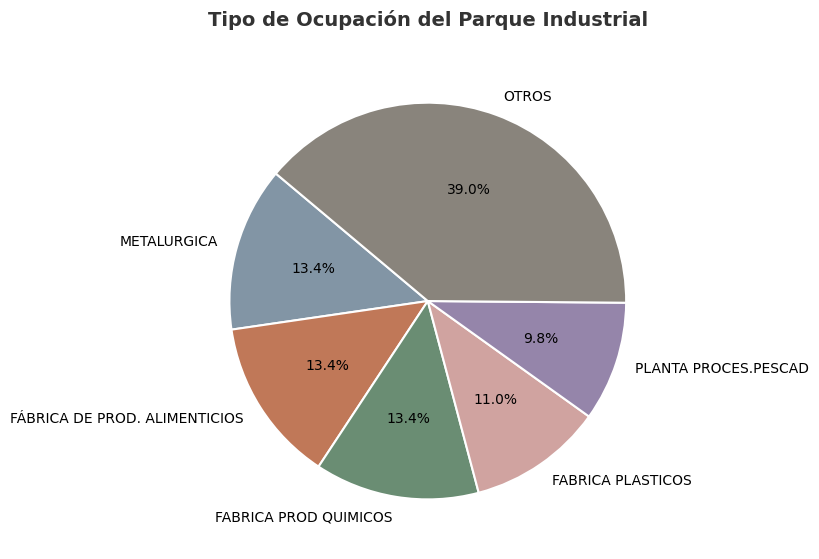

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

empresas_por_rubro = data_limpia.groupby('DENOMMULTIPROPOSITO')['NROIMPONIBLE'].nunique().reset_index()
empresas_por_rubro.columns = ['Rubro', 'Cantidad_Empresas']
empresas_por_rubro['Rubro'] = empresas_por_rubro['Rubro'].astype(str).str.strip()
empresas_por_rubro = empresas_por_rubro.sort_values(by='Cantidad_Empresas', ascending=False).reset_index(drop=True)

print("--- Cantidad de empresas por Tipo de Industria (Datos Brutos) ---")
display(empresas_por_rubro)

top_5 = empresas_por_rubro.head(5).copy()
otros_cantidad = empresas_por_rubro.iloc[5:]['Cantidad_Empresas'].sum()
otros_df = pd.DataFrame([{'Rubro': 'OTROS', 'Cantidad_Empresas': otros_cantidad}])

grafico_df = pd.concat([top_5, otros_df], ignore_index=True)

colores_pie = [colores_industria.get(rubro, '#89847C') for rubro in grafico_df['Rubro']]

plt.figure(figsize=(8, 8))
plt.pie(
    grafico_df['Cantidad_Empresas'],
    labels=grafico_df['Rubro'],
    autopct='%1.1f%%',
    startangle=140,
    colors=colores_pie,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Tipo de Ocupación del Parque Industrial', fontsize=14, fontweight='bold', pad=20, color='#333333')
plt.tight_layout()
plt.show()

### ▶ 2

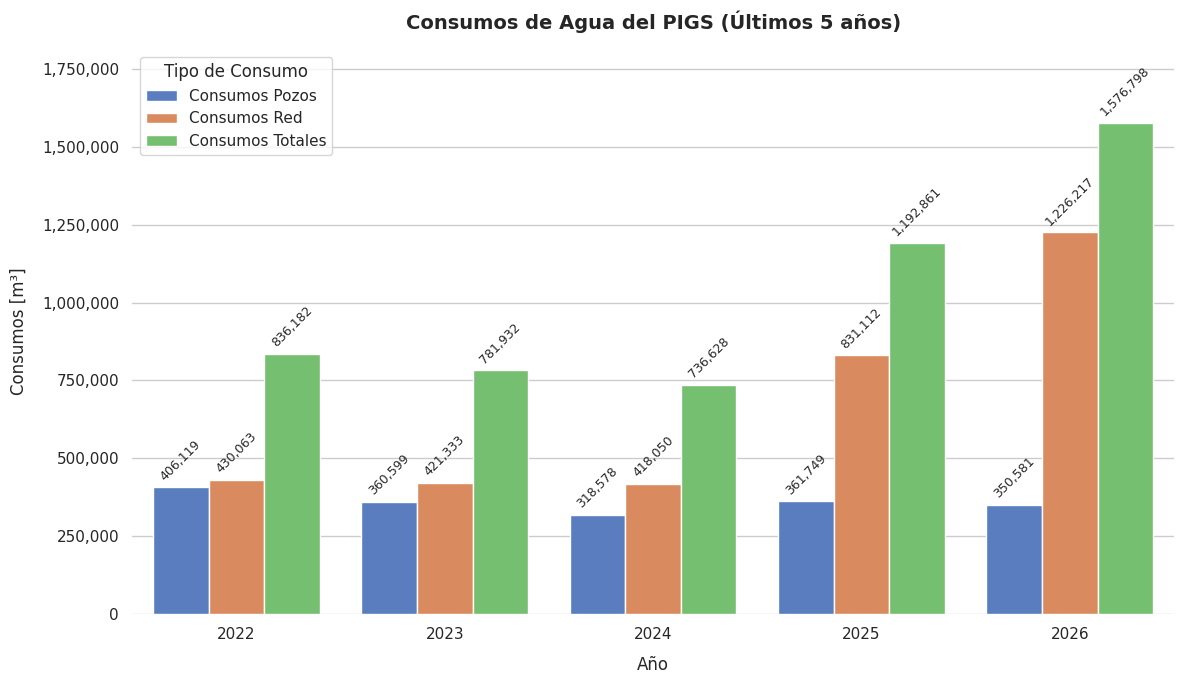

In [16]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

sns.set_theme(style="whitegrid")

consumo_anual = data_limpia.groupby('ANIO')[['CONSUMOPOZO', 'CONSUMORED', 'CONSUMOTOTAL']].sum().reset_index()

consumo_melted = consumo_anual.melt(
    id_vars='ANIO',
    value_vars=['CONSUMOPOZO', 'CONSUMORED', 'CONSUMOTOTAL'],
    var_name='Tipo de Consumo',
    value_name='Consumo'
)
nombres_map = {
    'CONSUMOPOZO': 'Consumos Pozos',
    'CONSUMORED': 'Consumos Red',
    'CONSUMOTOTAL': 'Consumos Totales'
}
consumo_melted['Tipo de Consumo'] = consumo_melted['Tipo de Consumo'].map(nombres_map)

plt.figure(figsize=(12, 7))
ax = sns.barplot(
    data=consumo_melted,
    x='ANIO',
    y='Consumo',
    hue='Tipo de Consumo',
    palette='muted'
)

ax.xaxis.grid(False)

ax.get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.title('Consumos de Agua del PIGS (Últimos 5 años)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Año', fontsize=12, labelpad=10)
plt.ylabel('Consumos [m³]', fontsize=12, labelpad=10)

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', label_type='edge', padding=3, fontsize=9, rotation=45)

plt.ylim(0, consumo_anual['CONSUMOTOTAL'].max() * 1.15)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

➕ El 78% del agua entregada en el año 2026 al Parque Industrial fue por RED y el 22% restante por POZOS de explotacion propia.

### ▶ 3


In [17]:
empresas_con_pozo = data_limpia[data_limpia['CONSUMOPOZO'] > 0]


cantidad_empresas_pozo = empresas_con_pozo['NROIMPONIBLE'].nunique()

print(f"Cantidad de empresas con registros de consumo de pozos propios: {cantidad_empresas_pozo}")

listado_empresas_pozo = empresas_con_pozo.groupby(['NROIMPONIBLE', 'DENOMMULTIPROPOSITO']).agg(
    CONSUMOPOZO_PROMEDIO_MES=('CONSUMOPOZO', 'mean')
).reset_index()

display(listado_empresas_pozo.style.format({'CONSUMOPOZO_PROMEDIO_MES': '{:.0f}'}))

Cantidad de empresas con registros de consumo de pozos propios: 7


,NROIMPONIBLE,DENOMMULTIPROPOSITO,CONSUMOPOZO_PROMEDIO_MES
0,60100000,FABRICA DE PAPAS FRI,14402
1,62442000,PLANTA PROCES.PESCAD,1096
2,62747000,FABRICA DE CERVEZA,2486
3,89671000,FABRICA PROD QUIMICOS,2088
4,89677000,PLANTA PROCES.PESCAD,1570
5,89695000,FABRICA PROD QUIMICOS,7568
6,89704000,FABRICA DE ALFAJORES,2878


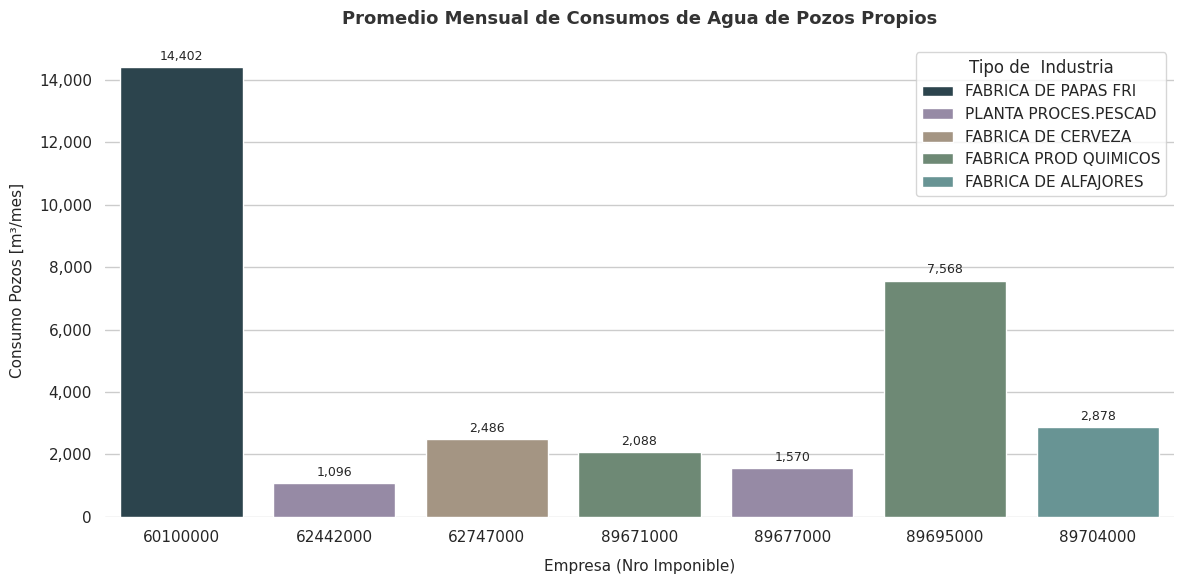

In [18]:

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Graficar
ax = sns.barplot(
    data=listado_empresas_pozo,
    x='NROIMPONIBLE',
    y='CONSUMOPOZO_PROMEDIO_MES',
    hue='DENOMMULTIPROPOSITO',
    dodge=False,
    palette=colores_industria
)

# Formatear el eje Y sin decimales y con separadores de miles
ax.get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.title('Promedio Mensual de Consumos de Agua de Pozos Propios', fontsize=13, fontweight='bold', pad=15, color='#333333')
plt.xlabel('Empresa (Nro Imponible)', fontsize=11, labelpad=10)
plt.ylabel('Consumo Pozos [m³/mes]', fontsize=11, labelpad=10)

plt.legend(title="Tipo de  Industria", loc='upper right')

# Agregar las etiquetas de valor sobre cada barra sin decimales
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', label_type='edge', padding=3, fontsize=9)

ax.xaxis.grid(False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

### ▶ 4

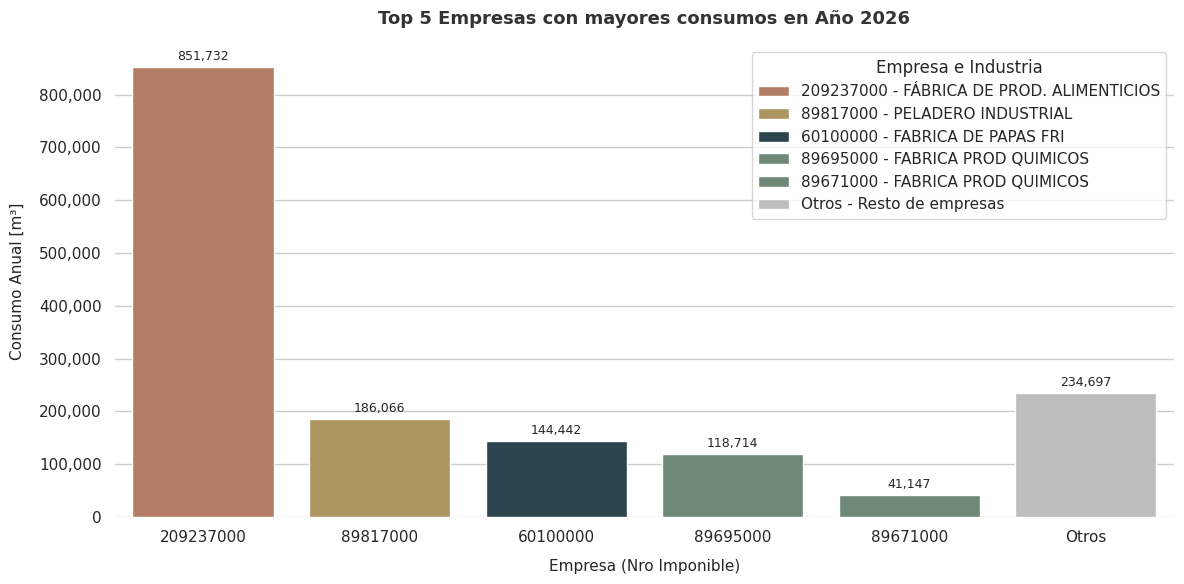

In [19]:
data_2026 = data_limpia[data_limpia['ANIO'] == 2026]
consumo_empresas = data_2026.groupby(['NROIMPONIBLE', 'DENOMMULTIPROPOSITO'])['CONSUMOTOTAL'].sum().reset_index()
consumo_empresas['DENOMMULTIPROPOSITO'] = consumo_empresas['DENOMMULTIPROPOSITO'].astype(str).str.strip()
consumo_empresas = consumo_empresas.sort_values(by='CONSUMOTOTAL', ascending=False).reset_index(drop=True)

top_5_empresas = consumo_empresas.head(5).copy()
otros_consumo_cant = consumo_empresas.iloc[5:]['CONSUMOTOTAL'].sum()
otros_emp_df = pd.DataFrame([{
    'NROIMPONIBLE': 'Otros',
    'DENOMMULTIPROPOSITO': 'Resto de empresas',
    'CONSUMOTOTAL': otros_consumo_cant
}])

grafico_barras_df = pd.concat([top_5_empresas, otros_emp_df], ignore_index=True)
grafico_barras_df['Descripcion_Empresa'] = grafico_barras_df.apply(
    lambda row: f"{row['NROIMPONIBLE']} - {row['DENOMMULTIPROPOSITO']}" if row['NROIMPONIBLE'] != 'Otros' else 'Otros - Resto de empresas',
    axis=1
)

colores_barras = [colores_industria.get(ind, '#bdbdbd') for ind in grafico_barras_df['DENOMMULTIPROPOSITO']]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=grafico_barras_df,
    x='NROIMPONIBLE',
    y='CONSUMOTOTAL',
    hue='Descripcion_Empresa',
    dodge=False,
    palette=colores_barras
)

ax.get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

plt.title('Top 5 Empresas con mayores consumos en Año 2026', fontsize=13, fontweight='bold', pad=15, color='#333333')
plt.xlabel('Empresa (Nro Imponible)', fontsize=11, labelpad=10)
plt.ylabel('Consumo Anual [m³]', fontsize=11, labelpad=10)

plt.legend(title="Empresa e Industria", loc='upper right')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', label_type='edge', padding=3, fontsize=9)

ax.xaxis.grid(False)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()


👀 Se observa que una sola empresa (209237000) de produccion de alimentos, representa el 54% del consumo total del Parque Industrial en el año 2026.






### ▶ 5

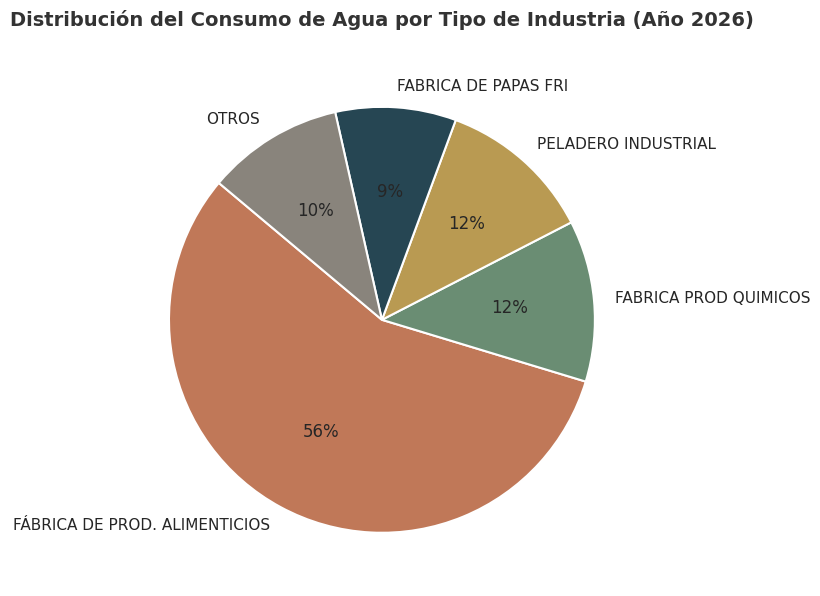

In [20]:

data_2026 = data_limpia[data_limpia['ANIO'] == 2026]

# Agrupar por tipo de industria (rubro) y sumar consumos
consumo_por_rubro = data_2026.groupby('DENOMMULTIPROPOSITO')['CONSUMOTOTAL'].sum().reset_index()
consumo_por_rubro.columns = ['Rubro', 'Consumo_Total']
consumo_por_rubro['Rubro'] = consumo_por_rubro['Rubro'].astype(str).str.strip()
consumo_por_rubro = consumo_por_rubro.sort_values(by='Consumo_Total', ascending=False).reset_index(drop=True)

# Obtener el Top 4 y agrupar el resto en OTROS
top_4 = consumo_por_rubro.head(4).copy()
otros_consumo = consumo_por_rubro.iloc[4:]['Consumo_Total'].sum()
otros_df = pd.DataFrame([{'Rubro': 'OTROS', 'Consumo_Total': otros_consumo}])

grafico_torta_df = pd.concat([top_4, otros_df], ignore_index=True)

# Asignar colores según el diccionario predefinido
colores_pie = [colores_industria.get(rubro, '#89847C') for rubro in grafico_torta_df['Rubro']]

# Generar el gráfico de torta
plt.figure(figsize=(8, 8))
plt.pie(
    grafico_torta_df['Consumo_Total'],
    labels=grafico_torta_df['Rubro'],
    autopct='%1.0f%%',
    startangle=140,
    colors=colores_pie,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)

plt.title('Distribución del Consumo de Agua por Tipo de Industria (Año 2026)', fontsize=14, fontweight='bold', pad=20, color='#333333')
plt.tight_layout()
plt.show()

## 🔚 Conclusiones

*  Se evidencia un crecimiento significativo del consumo de agua del Parque Industrial General Savio (PIGS), del orden del 214 % respecto del año 2024. Este incremento se encuentra asociado al emplazamiento de nuevas empresas de gran envergadura, acompañado por la ejecución de obras de infraestructura sanitaria durante dicho período, destinadas a ampliar la capacidad de prestación del servicio.

*  Se observa una reducción en la participación de los consumos provenientes de pozos de explotación propia respecto del consumo total de agua del Parque Industrial, pasando del orden del 43 % en el año 2024 al 22 % en el año 2026.

* Del análisis realizado se desprende que el consumo de agua del PIGS se encuentra altamente concentrado en un número reducido de empresas. En consecuencia, no resulta adecuado establecer valores de «consumos típicos» generalizados en función del tipo de industria, dado que la demanda depende fundamentalmente de la escala de cada establecimiento y de los requerimientos específicos de agua asociados a sus procesos productivos.

  Esta particularidad pone de manifiesto la necesidad de que la empresa prestadora del servicio solicite, como parte del proceso de evaluación de factibilidad, un informe detallado que permita cuantificar y justificar los requerimientos de consumo de agua de cada nuevo establecimiento.


In [21]:
from google.colab import files

# Guardar el DataFrame como Excel para el Power Bi(.xlsx)
data_limpia.to_excel('data_limpia.xlsx', index=False)

files.download('data_limpia.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>